In [1]:
import os
import pandas as pd
from scipy.stats import gaussian_kde

In [ ]:
DATA_DIR = '/home/mkeoliya/projects/mc-med/data/'

DEMOGRAPHICS

In [2]:
DATA_DIR = '/home/mkeoliya/projects/mc-med/mc-med-1.0.0/data'

In [19]:
TASK = 'decompensation' # decompensation

In [20]:
label_df = pd.read_parquet(f'data/{TASK}.parquet')

In [21]:
if TASK == 'eSOFA':
    label_df['Time'] = label_df.apply(lambda x: x['Trigger_time'] if x['Label'] else x['Sample_time'], axis=1)
elif TASK == 'decompensation':
    label_df['Time'] = label_df.apply(lambda x: x['Criteria_from_arrive'] if x['Label'] else x['Sample_time'], axis=1)

In [22]:
rads_df = pd.read_csv(os.path.join(DATA_DIR, 'rads.csv'))
rads_df = rads_df[rads_df['CSN'].isin(label_df['CSN'])]

In [23]:
visits_df = pd.read_csv(os.path.join(DATA_DIR, 'visits.csv'), usecols=['CSN', 'Age', 'Gender', 'Race', 'Ethnicity', 'Arrival_time'])
visits_df = visits_df[visits_df['CSN'].isin(label_df['CSN'])]

In [24]:
ETHNICITY = ['Non-Hispanic/Non-Latino', 'Hispanic/Latino']

In [25]:
RACES = ['Other', 'White', 'Black or African American', 'Asian',
        'Native Hawaiian or Other Pacific Islander', 'American Indian or Alaska Native']

In [26]:
visits_df['Ethnicity'] = visits_df['Ethnicity'].apply(lambda x: x if x in ETHNICITY else 'Unknown')
visits_df['Race'] = visits_df['Race'].apply(lambda x: x if x in RACES else 'Unknown')

In [ ]:
visits_df[['CSN', 'Age', 'Gender', 'Race', 'Ethnicity']].to_parquet(f'data/{TASK}_demo.parquet')

TEXT

In [28]:
rads_df = rads_df.merge(visits_df[['CSN', 'Arrival_time']], on='CSN')

In [29]:
rads_df['Order_time'] = pd.to_datetime(rads_df['Order_time'].apply(lambda x: str(int(x[:4]) - 500) + x[4:]))
rads_df['Result_time'] = pd.to_datetime(rads_df['Result_time'].apply(lambda x: str(int(x[:4]) - 500) + x[4:]))
rads_df['Arrival_time'] = pd.to_datetime(rads_df['Arrival_time'].apply(lambda x: str(int(x[:4]) - 500) + x[4:]))

In [30]:
rads_df['Order_time'] = rads_df['Order_time'] - rads_df['Arrival_time']
rads_df['Result_time'] = rads_df['Result_time'] - rads_df['Arrival_time']
rads_df = rads_df.drop(columns=['Arrival_time'])

In [31]:
rads_df['Order_time'] = rads_df['Order_time'].dt.total_seconds() / 3600
rads_df['Result_time'] = rads_df['Result_time'].dt.total_seconds() / 3600

In [32]:
rads_df = rads_df.merge(label_df[['CSN', 'Time']], on='CSN')
rads_df = rads_df[rads_df['Order_time'] <= (rads_df['Time'])]
rads_df = rads_df.drop(columns=['Time'])

In [33]:
rads_df.to_parquet(f'data/{TASK}_rads.parquet')

ADD WAVEFORMS

In [4]:
import wfdb
import numpy as np
from scipy.stats import linregress, kurtosis, skew

In [ ]:
def extract_stats(xs):
    xs = np.array(xs)
    x = np.arange(len(xs))
    slope, _, _, _, _ = linregress(x, xs)

    return {
        'min': xs.min(),
        'max': xs.max(),
        'mean': xs.mean(),
        'std': xs.std(),
        'median': np.median(xs),
        'skew': skew(xs),
        'kurtosis': kurtosis(xs),
        'slope': slope,
        'qr_25': np.quantile(xs, 0.25),
        'qr_75': np.quantile(xs, 0.75),
    }

In [47]:
DATA_DIR = '/home/mkeoliya/projects/mc-med/mc-med-1.0.0'
# TASK = 'decompensation'
TASK = 'eSOFA'

In [44]:
label_df = pd.read_parquet(os.path.join('/home/mkeoliya/projects/mc-med/data', f'{TASK}.parquet'))  
label_df['Time'] = label_df.apply(lambda x: x['Trigger_time'] if x['Label'] else x['Sample_time'], axis=1)
label_ids = label_df['CSN'].unique()

In [48]:
visits_df = pd.read_csv(os.path.join(DATA_DIR, 'data', 'visits.csv'), usecols=['CSN', 'Arrival_time'])
visits_df = visits_df[visits_df['CSN'].isin(label_ids)]
visits_df['Arrival_time'] = pd.to_datetime(visits_df['Arrival_time'].apply(lambda x: str(int(x[:4]) - 500) + x[4:]))

In [49]:
summary_df = pd.read_csv(os.path.join(DATA_DIR, 'data', 'waveform_summary.csv'))
summary_df = summary_df[(summary_df['CSN'].isin(label_ids)) & (summary_df['Type'] == 'II')]

In [50]:
waveform_dict = {}
for csn in summary_df['CSN'].unique():
    data_paths = (os.path.join(DATA_DIR, 'waveforms', str(csn)[-3:], str(csn), 'II'))
    arrival_time = visits_df[visits_df['CSN'] == csn].iloc[0].Arrival_time
    arrival_time = arrival_time.replace(tzinfo=None)

    for data_path in os.listdir(data_paths):
        if data_path[-3:] == 'dat':
            record_path = os.path.join(data_paths, data_path[:-4])
            record = wfdb.rdrecord(record_path)
            duration = (len(record.p_signal.reshape(-1)) / 250) / 3600

            base_time = (record.base_datetime - pd.DateOffset(years=500) - arrival_time).total_seconds()
            base_time = base_time / 3600
        waveform_dict[data_path[:-4]] = base_time, base_time + duration

In [53]:
import pickle

In [54]:
with open(f'{TASK}_dict.pkl', 'wb') as f:
    pickle.dump(waveform_dict, f)

In [ ]:
waveform_dict = {}
for csn in summary_df['CSN'].unique():
    data_paths = (os.path.join(DATA_DIR, 'waveforms', str(csn)[-3:], str(csn), 'II'))
    arrival_time = visits_df[visits_df['CSN'] == csn].iloc[0].Arrival_time
    arrival_time = arrival_time.replace(tzinfo=None)
    signals = []
    
    for data_path in os.listdir(data_paths):
        if data_path[-3:] == 'dat':
            record_path = os.path.join(data_paths, data_path[:-4])
            record = wfdb.rdrecord(record_path)
            signal = record.p_signal.reshape(-1)

            base_time = (record.base_datetime - pd.DateOffset(years=500) - arrival_time).total_seconds()
            num_samples = len(signal)
            time = np.linspace(0, num_samples / record.fs, num_samples) + base_time
            # mask = time < N 
            
            signal = signal[mask]
            signals += list(signal)
    
    if len(signals) > 0:
        waveform_dict[csn] = signals

SEPSIS

In [30]:
label_df = pd.read_parquet(os.path.join(DATA_DIR, 'eSOFA.parquet'))

In [31]:
neg_df = label_df[label_df['Trigger_time'].isna()]
pos_df = label_df[label_df['Trigger_time'] >= 1.5]

In [ ]:
original = (pos_df['Trigger_time'].values)
kde = gaussian_kde(original)

In [34]:
neg_df['Sample_time'] = kde.resample(size=len(neg_df)).flatten()

/tmp/ipykernel_1966342/2663040190.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  neg_df['Sample_time'] = kde.resample(size=len(neg_df)).flatten()


In [ ]:
df = pd.concat([neg_df, pos_df])
df = label_df.merge(df[['CSN', 'Sample_time']], on='CSN', how='left')

In [41]:
df.to_parquet('data/eSOFA.parquet')

PLOT DISTRIBUTIONS

In [20]:
import numpy as np
import matplotlib.pyplot as plt

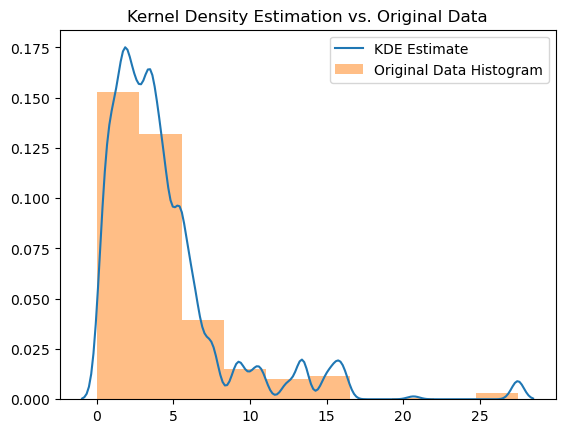

In [21]:
x = np.linspace(min(original) - 1, max(original) + 1, 200)
plt.plot(x, kde(x), label='KDE Estimate')
plt.hist(original, bins=10, density=True, alpha=0.5, label='Original Data Histogram')
plt.legend()
plt.title("Kernel Density Estimation vs. Original Data")
plt.show()